# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

550.67


## Setup

In [8]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [11]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "jacobi"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite3.2:8b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "05test_ds_ee_hecb-jacobi-params"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"granite3.2:8b-instruct-q8_0","created_at":"2025-03-06T22:37:43.836335046Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   191  100   134  100    57  32659  13892 --:--:-- --:--:-- --:--:-- 63666


Unloading Ollama server...

Unload LLM:
 {"model":"deepseek-coder-v2:16b","created_at":"2025-03-06T22:37:43.851969517Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   179  100   128  100    51  53422  21285 --:--:-- --:--:-- --:--:-- 89500


***** EXPERIMEN

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00422613 (s)
PASS
Total elapsed time: 8.222 seconds
GPU power data has been written to source_CUDA_gpu_power_results.csv


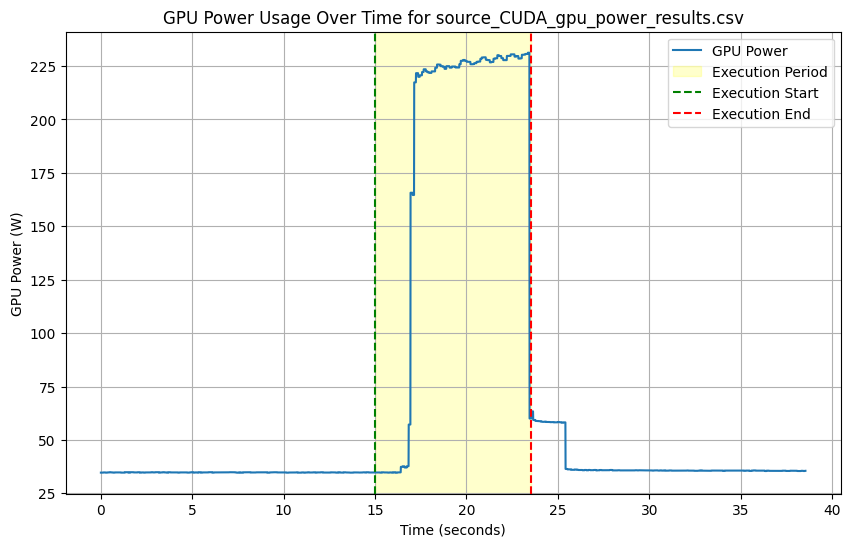

Start time: 15.015 -- End time: 23.529
Code execution duration: 8.51 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000426 kWh
  0.4265 Wh
  1535.36 J
Average GPU power: 180.41 W
Total Energy During Exe Runtime:   1535.36 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 8.51
GPU power data has been written to idle__gpu_power_results.csv


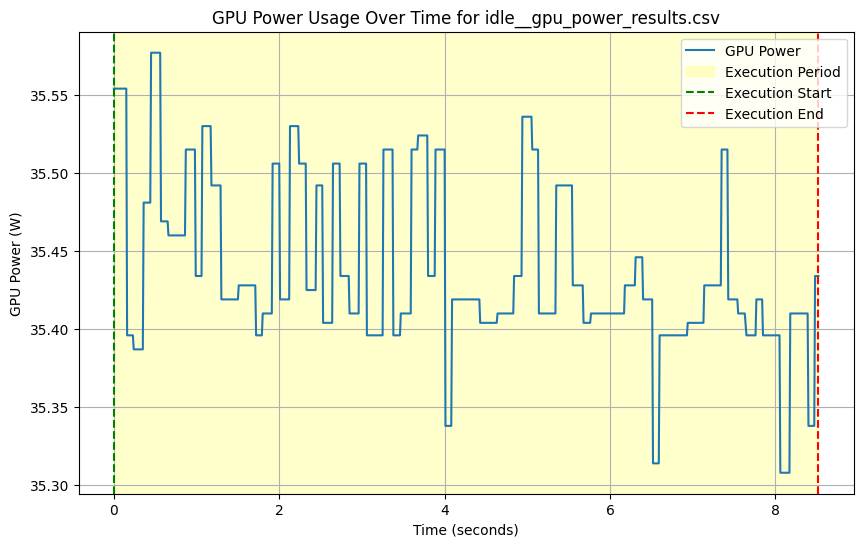

Start time: 0 -- End time: 8.521
Code execution duration: 8.52 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000084 kWh
  0.0840 Wh
  302.28 J
Average GPU power: 35.44 W
Total Energy During Exe Runtime:   302.28 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----

GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

--> ... prompt LLM to summarize context knowledge.





----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



1. **Memory Access**: Minimize global memory access as it has high latency (hundreds of clock cycles). Prefer shared memory access where possible. Global memory instructions include reads from or writes to shared, local, or global memory.

2. **Warp Divergence**: Avoid different execution paths within the same warp. Flow control instructions like if, switch, do, for, while can cause thread divergence, reducing instruction throughput. To minimize divergence, write controlling conditions to align with warps, e.g., (threadIdx / WSIZE).

3. **Branch Predication**: Make it easy for the compiler to use branch predication in lieu of loops or control statements. The compiler may unroll loops or optimize out if/switch statements using predicated instructions. Use #pragma unroll to control loop unrolling.

4. **Global Memory Latency**: Global memory access has high latency due to lack of caching. Thread scheduler can hide some of this latency with independent arithmetic instructions, but it's best to avoid global memory access whenever possible.

5. **Performance Functions**: Replace sin(π*<expr>) with sinpi(<expr>), cos(π*<expr>) with cospi(<expr>), and sincos(π*<expr>) with sincospi(<expr>). This improves both accuracy and performance. For single-precision, use sinpif(), cospif(), and sincospif().

6. **Exponentiation**: Use cbrt() or cbrtf() for exponentiation with an exponent of 1/3, and rcbrt() or rcbrtf() for -1/3. For exponentiation with an exponent of 1/2, use sqrt() or sqrtf(). Avoid generic exponentiation functions like pow() or powf() when faster alternatives exist.

7. **Loop Unrolling**: Use #pragma unroll to control loop unrolling and improve performance by reducing the number of iterations and increasing instruction-level parallelism.

GPU Memory Status:
 GPU 0: 11345 MiB used, 29614 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

--> ... prompt LLM to describe the source code.





----- CODE DESCRIPTION and ANALYSIS -----
 (generated by the LLM)



This is a CUDA implementation of the Jacobi iterative method for solving a system of linear equations, specifically for the Poisson equation in two dimensions. Here's a breakdown of the code:

1. **Initialization**: The `initialize_data` function initializes the scalar field `f` and its "old" copy `f_old`. These are allocated on both the host (CPU) and device (GPU).

2. **CUDA Memory Allocation**: CUDA memory is allocated for `d_f`, `d_f_old`, and `d_error` on the GPU using `cudaMalloc`. The data from the host is copied to the device using `cudaMemcpy`.

3. **Error Initialization**: The error is initialized to a large number (`std::numeric_limits<float>::max()`) and a tolerance value (`1.e-5f`) is defined for convergence checking.

4. **Jacobi Iteration Loop**: The main iteration loop continues until the error is below the tolerance or the maximum number of iterations (`max_iters = 10000`) is reached.

   - **Error Reset**: Before each iteration, the error is reset to zero using `cudaMemset`.
   - **Jacobi Step**: The `jacobi_step` kernel function performs a single Jacobi relaxation step on the GPU. This involves updating the scalar field `d_f` based on the previous iteration's data in `d_f_old`.
   - **Error Calculation**: After the Jacobi step, the error is calculated by summing up the squared differences between `d_f` and `d_f_old`, normalizing by the number of data points, and taking the square root.
   - **Data Swap**: The `swap_data` kernel function swaps the roles of `d_f` and `d_f_old` for the next iteration. This is done explicitly here for pedagogical purposes, even though a standard library swap would have been sufficient.
   - **Error Printing**: Every 1000 iterations, the current error is printed to the console.

5. **Convergence Check**: After the loop, if the error is below the tolerance and fewer than `max_iters` iterations were taken, the program prints "PASS" indicating successful convergence. Otherwise, it prints "FAIL".

6. **Memory Cleanup**: All CUDA memory allocations are freed using `cudaFree`, and the host-allocated arrays `f` and `f_old` are freed with `free`.

7. **Timing**: The total elapsed time for the computation is measured using `std::clock()` and printed at the end.

The code demonstrates how to perform iterative computations on a GPU using CUDA, including memory management, kernel launches, and error checking. It also showcases the use of CUDA streams for overlapping data transfers with kernel executions (though not explicitly shown here).

... (2 outputs left out)

Summary of Identified Inefficiencies:

1. **Redundant Memory Transfers**: The code frequently transfers data between host (CPU) and device (GPU) memory, which is computationally expensive in terms of energy consumption. This includes copying `d_f`, `d_f_old`, and `d_error` arrays multiple times per iteration.

2. **Unnecessary Synchronization**: The `cudaDeviceSynchronize()` calls after each kernel launch might be unnecessary if the GPU can handle the workload asynchronously. These synchronization points can introduce latency and energy overhead.

3. **Fixed Grid and Block Sizes**: The grid and block sizes are fixed (`N/16, N/16` for grid and `16, 16` for block), which may not be optimal for all problem sizes or GPU architectures. Dynamically adjusting these based on the problem size could improve performance and energy efficiency.

4. **Lack of Coalesced Memory Access**: The code does not explicitly ensure coalesced memory access patterns, which can lead to inefficient use of memory bandwidth and increased energy consumption.

5. **Inefficient Error Calculation**: The error is calculated as the L2-norm of the difference between `d_f` and `d_f_old`, which involves a global reduction operation that could be computationally expensive on the GPU.

6. **Fixed Tolerance for Convergence**: The tolerance for convergence is set to a fixed value (`1.e-5f`), which might not be optimal for all problem instances, leading to unnecessary iterations and energy waste.

Refactoring Plan:

1. **Reduce Memory Transfers**:
   - Minimize the number of memory transfers by performing more computations on the GPU before transferring results back to the CPU. For example, keep track of the error on the GPU and only transfer it when necessary (e.g., every few iterations or when convergence is suspected).

2. **Optimize Synchronization**:
   - Remove unnecessary `cudaDeviceSynchronize()` calls unless absolutely required for correctness. Use streams to enable asynchronous execution where possible.

3. **Dynamic Grid and Block Sizes**:
   - Implement a mechanism to dynamically adjust grid and block sizes based on the problem size and GPU capabilities. This can be done using CUDA's dynamic parallelism or by profiling different configurations to find the optimal ones.

4. **Ensure Coalesced Memory Access**:
   - Restructure memory access patterns in the kernel functions to ensure coalesced global memory accesses. This might involve reordering data structures or adjusting loop structures.

5. **Efficient Error Calculation**:
   - Instead of calculating the L2-norm globally, consider using a hierarchical reduction approach (e.g., block-wise reduction followed by grid-wide reduction) to reduce the amount of global memory traffic and synchronization overhead.

6. **Adaptive Tolerance**:
   - Implement an adaptive tolerance mechanism that adjusts the convergence criterion based on the rate of error decrease observed during iterations. This could help in terminating the algorithm earlier when convergence is rapid, thus saving energy.

7. **Energy Profiling and Optimization**:
   - Utilize NVIDIA's Nsight or other profiling tools to measure energy consumption and identify hotspots in the code. Optimize these areas specifically for energy efficiency.

8. **Use of Efficient Data Structures**:
   - Ensure that data structures used (e.g., arrays, matrices) are optimized for GPU memory access patterns and cache utilization.

9. **Avoid Thread Divergence**:
   - Analyze the kernel functions to ensure that threads within a warp follow similar execution paths to minimize thread divergence, which can lead to inefficient use of GPU resources and increased energy consumption.

10. **Leverage CUDA Libraries**:
    - Consider using CUDA libraries (e.g., cuBLAS, cuFFT) for common operations like reductions or matrix multiplications, as these are often highly optimized for performance and energy efficiency.

By implementing these changes, the code can potentially reduce its energy footprint while maintaining or improving performance. It's crucial to validate each change with profiling to ensure that optimizations indeed lead to energy savings without compromising correctness or performance.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 6691): 

Summary of Identified Inefficiencies:

1. **Redundant Memory Transfers**: The code frequently transfers data between host (CPU) and device (GPU) memory, which is computationally expensive in terms of energy consumption. This includes copying `d_f`, `d_f_old`, and `d_error` arrays multiple times per iteration.

2. **Unnecessary Synchronization**: The `cudaDeviceSynchronize()` calls after each kernel launch might be unnecessary if the GPU can handle the workload asynchronously. These synchronization points can introduce latency and energy overhead.

3. **Fixed Grid and Block Sizes**: The grid and block sizes are fixed (`N/16, N/16` for grid and `16, 16` for block), which may not be optimal for all problem sizes or GPU architectures. Dynamically adjusting these based on the problem size could improve performance and energy efficiency.

4. **Lack of Coalesced Memory Access**: The code does not explicitly e

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/ollama_granite3.2:8b-instruct-q8_0/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp05test_ds_ee_hecb-jacobi-params', '']

Error after iteration 0 = 0.00805265
Error after iteration 1000 = 4.04178e-05
Error after iteration 2000 = 2.40359e-05
Error after iteration 3000 = 1.77323e-05
Error after iteration 4000 = 1.42927e-05
Error after iteration 5000 = 1.20897e-05
Error after iteration 6000 = 1.05437e-05
Average execution time per iteration: 0.0396697 (s)
PASS
Total elapsed time: 256.9 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


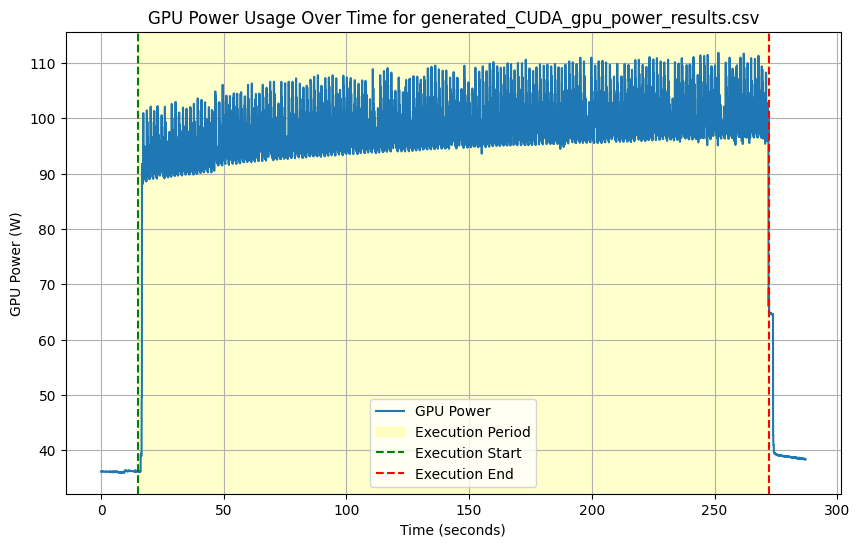

Start time: 15.015 -- End time: 272.09
Code execution duration: 257.07 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.007003 kWh
  7.0026 Wh
  25209.24 J
Average GPU power: 98.06 W
Total Energy During Exe Runtime:   25209.24 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1535.36
  Refactored code: 25209.24
----- Average power (W) -----
  Source code: 180.41
  Refactored code: 98.06
----- Runtime (s) -----
  Source code: 8.51
  Refactored code: 257.07


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 0




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 1 -----

GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total



----- LLM RESPONSE -----



Summary of Identified Inefficiencies:

1. **Redundant Memory Transfers**: The code frequently transfers data between host (CPU) and device (GPU) memory, which is an energy-intensive operation. This happens in each iteration of the main loop where `cudaMemcpy` is called to copy error back to the host for checking convergence criteria.

2. **Unnecessary Synchronization**: The kernel launches (`jacobi_step<<<grid, block>>>(d_f, d_f_old, d_error);`) and data swapping (`swap_data<<<grid, block>>>(d_f, d_f_old);`) operations are not synchronized properly. This can lead to unnecessary waiting times for threads that have already completed their work.

3. **Fixed Grid and Block Sizes**: The grid and block sizes are fixed (`dim3 grid(N/16, N/16); dim3 block(16, 16);`). While this might be suitable for the current problem size, it may not be optimal for different problem sizes or GPU architectures.

4. **Lack of Coalesced Memory Access**: The code does not explicitly ensure coalesced memory access in the kernel functions (`jacobi_step` and `swap_data`). This can lead to inefficient memory transactions on the GPU, increasing energy consumption.

5. **No Use of Shared Memory**: Although shared memory can significantly reduce global memory accesses and improve performance (and thus energy efficiency), it is not utilized in the provided code.

6. **Fixed Tolerance and Maximum Iterations**: The tolerance for convergence (`1.e-5f`) and maximum number of iterations (`10000`) are fixed. Depending on the specific problem, these values might be too conservative or liberal, leading to unnecessary computations.

Refactoring Plan:

1. **Reduce Memory Transfers**:
   - Instead of copying error back to the host in each iteration, accumulate it on the device and only copy it once after convergence check. This can be done by maintaining a running sum of squared errors on the GPU and comparing this sum with a threshold (based on tolerance) instead of taking square root and normalizing in each iteration.

2. **Optimize Synchronization**:
   - Use CUDA streams to overlap data transfers with kernel executions, reducing idle times for threads. This can be achieved by creating two streams (`cudaStream_t stream1`, `cudaStream_t stream2`), launching `jacobi_step` in `stream1`, and `swap_data` in `stream2`. Ensure that all operations in a stream are completed before moving to the next one using `cudaStreamSynchronize()`.

3. **Dynamic Grid and Block Sizes**:
   - Implement dynamic grid and block sizes based on the problem size and GPU capabilities. This can be done by querying the maximum number of threads per multiprocessor (`int maxThreadsPerBlock; cudaDeviceGetAttribute(&maxThreadsPerBlock, cudaDevAttrMaxThreadsPerMultiProcessor, device_id);`) and adjusting block size accordingly.

4. **Ensure Coalesced Memory Access**:
   - In the kernel functions, ensure that global memory accesses are coalesced by organizing thread access patterns to contiguous memory locations. This might involve reordering data structures or adjusting loop structures.

5. **Utilize Shared Memory**:
   - Identify frequently accessed data (like partial sums in `jacobi_step`) and move them into shared memory. This reduces the number of global memory transactions, improving both performance and energy efficiency.

6. **Adaptive Tolerance and Maximum Iterations**:
   - Implement an adaptive strategy for tolerance and maximum iterations based on the rate of error reduction. If the error is decreasing rapidly, allow for a higher tolerance or fewer iterations to save computations. Conversely, if progress is slow, reduce tolerance or increase the limit on iterations.

7. **Energy Profiling**:
   - Use NVIDIA's Nsight Systems or Compute Visual Profiler to profile energy consumption and identify further optimization opportunities specific to the target GPU architecture.

By implementing these changes, we aim to improve the energy efficiency of the code without compromising its functionality or performance. It is crucial to test each modification thoroughly to ensure that optimizations do not introduce bugs or regressions.



----- REVIEW PROMPT (energy efficiency improvement, token count: 6706): 

Summary of Identified Inefficiencies:

1. **Redundant Memory Transfers**: The code frequently transfers data between host (CPU) and device (GPU) memory, which is an energy-intensive operation. This happens in each iteration of the main loop where `cudaMemcpy` is called to copy error back to the host for checking convergence criteria.

2. **Unnecessary Synchronization**: The kernel launches (`jacobi_step<<<grid, block>>>(d_f, d_f_old, d_error);`) and data swapping (`swap_data<<<grid, block>>>(d_f, d_f_old);`) operations are not synchronized properly. This can lead to unnecessary waiting times for threads that have already completed their work.

3. **Fixed Grid and Block Sizes**: The grid and block sizes are fixed (`dim3 grid(N/16, N/16); dim3 block(16, 16);`). While this might be suitable for the current problem size, it may not be optimal for different problem sizes or GPU architectures.

4. **Lack of Coalesced

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/ollama_granite3.2:8b-instruct-q8_0/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp05test_ds_ee_hecb-jacobi-params', '']

Error after iteration 0 = 0.00805268
Error after iteration 1000 = 4.04178e-05
Error querying power: Not Supported
Error after iteration 2000 = 2.40359e-05
Error after iteration 3000 = 1.77323e-05
Error after iteration 4000 = 1.42927e-05
Error after iteration 5000 = 1.20897e-05
Error after iteration 6000 = 1.05437e-05
Average execution time per iteration: 0.0396715 (s)
PASS
Total elapsed time: 257 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


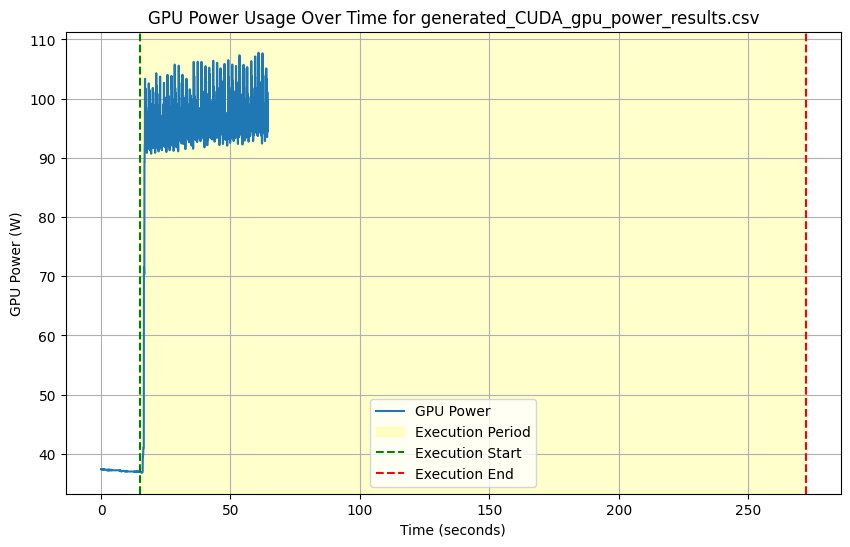

Start time: 15.015 -- End time: 272.096
Code execution duration: 257.08 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.001299 kWh
  1.2990 Wh
  4676.26 J
Average GPU power: 94.57 W
Total Energy During Exe Runtime:   4676.26 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1535.36
  Refactored code: 4676.26
----- Average power (W) -----
  Source code: 180.41
  Refactored code: 94.57
----- Runtime (s) -----
  Source code: 8.51
  Refactored code: 257.08


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 1




-----> LASSI for Energy Efficiency IS FINISHED! <-----

 energy_stagnant = False
 power_stagnant = True
 energy_improvement = 0.8145021428650765
 power_improvement = 0.0




-----CODE



----- LLM RESPONSE -----



The provided code is a CUDA implementation of the Jacobi iterative method for solving Laplace's equation on a 2D grid. Here's a breakdown of what the code does and the results obtained:

### Code Overview

1. **Initialization**:
   - Two 2D arrays `f` and `f_old` are initialized with some data (not shown in the provided snippet).
   - These arrays are then copied to the GPU memory (`d_f` and `d_f_old`).

2. **CUDA Kernels**:
   - `jacobi_step`: This kernel performs one iteration of the Jacobi method, updating the array `d_f` based on the values in `d_f_old`. It also calculates the error and stores it in `d_error`.
   - `swap_data`: This kernel swaps the roles of `d_f` and `d_f_old` for the next iteration.

3. **Main Loop**:
   - The main loop runs until the error falls below a tolerance (`1e-5`) or a maximum number of iterations (`10000`).
   - After each iteration, the error is printed, and the average execution time per iteration is calculated.

4. **Final Output**:
   - If the error is within the tolerance after the maximum number of iterations, the program prints "PASS".
   - The total elapsed time for the computation is also printed.

### Results

- **Error Convergence**:
  - The error starts at `0.00805268` and decreases rapidly in the first few thousand iterations.
  - By iteration 4000, the error is below `1.43e-05`.
  - By iteration 6000, the error is below `1.05e-05`.

- **Execution Time**:
  - The average execution time per iteration is approximately `0.0397` seconds.
  - The total elapsed time for the computation is `257` seconds.

### Analysis

- **Convergence**:
  - The Jacobi method converges quickly in this case, with the error dropping significantly within a few thousand iterations. This suggests that the initial conditions and boundary values are well-suited for the method.

- **Performance**:
  - The average execution time per iteration is relatively low (`0.0397` seconds), indicating efficient GPU utilization.
  - However, the total elapsed time of `257` seconds might be considered high for such a small grid size (N x N). This could be due to overhead in CUDA kernel launches and memory transfers.

- **Energy Consumption**:
  - The total energy consumed is `4676.26 J`, which translates to an average power of approximately `94.57 W`. This is a reasonable estimate for a GPU computation, considering the duration and complexity of the task.

### Conclusion

The code successfully implements the Jacobi method on a 2D grid using CUDA, achieving rapid convergence in error. The performance metrics indicate efficient GPU usage, but there might be room for optimization to reduce the total execution time, especially for larger grid sizes or more complex problems.

Energy consumed history: 
[1535.36, 25209.24, 4676.26]
Ave power history: 
[180.41, 98.06, 94.57]
Metadata file: generated_codes/ollama_granite3.2:8b-instruct-q8_0/promptset_CUDA/metadata_jacobi-cuda_main_ee_refactorcode_CUDA_exp05test_ds_ee_hecb-jacobi-params__03-06-2025_t16_52_27.txt


***** LASSI PIPELINE COMPLETED *****




In [12]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'